# Latihan Bab 7: Pemodelan Kualitas Air dengan DATA SIMULASI
**Buku:** *Penginderaan Jauh untuk Pemodelan Kualitas Air: Konsep, Kalibrasi, Validasi, dan Praktik di Sungai, Danau, Waduk, dan Pesisir Indonesia*, Bab 7, subbab 7.6

> ⚠️ **PERHATIAN.** Semua data di notebook ini **dibangkitkan komputer untuk latihan**. Data ini bukan pengukuran dan tidak menggambarkan Sungai Porong atau Waduk Sutami. Angka hasilnya **tidak boleh dikutip** sebagai kinerja algoritma di perairan nyata.

**Cara memakai:** klik **Runtime → Run all**, atau jalankan sel satu per satu dengan **Shift+Enter**. Semua paket yang diperlukan sudah tersedia di Google Colab.

**Alur notebook**
1. Model bio-optik ilustratif (konsentrasi → reflektansi)
2. Pembangkit data simulasi
3. Memuat data latih (dari link unduhan, berkas CSV, atau dibangkitkan ulang)
4. Metrik dan validasi silang (Bab 6)
5. Kasus 1: sungai sintetik, TSS
6. Kasus 2: waduk sintetik, klorofil-a
7. Unduh hasil
8. Latihan untuk mahasiswa (pembahasan di Lampiran A)

In [1]:
import io, os, json, zipfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, LeaveOneGroupOut

plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
LBL = "DATA SIMULASI — bukan pengukuran"
def stamp(fig):
    fig.text(0.995, 0.005, LBL, ha="right", va="bottom", fontsize=7, color="#B5403A", style="italic")
pd.set_option("display.precision", 4)
print("Siap.")

Siap.


## 1. Model bio-optik ilustratif
Reflektansi dihitung dari sifat optik inheren (IOP) dengan hubungan Gordon et al. (1988):

$$r_{rs} \approx 0{,}0949\,u + 0{,}0794\,u^2, \qquad u = \frac{b_b}{a + b_b}$$

lalu dikonversi menjadi reflektansi di atas permukaan: $R_{rs} = 0{,}52\,r_{rs} / (1 - 1{,}7\,r_{rs})$.

Absorpsi $a$ dan hamburan balik $b_b$ dihitung dari TSS, klorofil-a, dan CDOM. Nilai IOP spesifik di bawah ini **ilustratif**: dipilih agar perilaku spektralnya masuk akal (Bab 1–2), bukan diukur di perairan mana pun. Kanal mengikuti Sentinel-2 MSI.

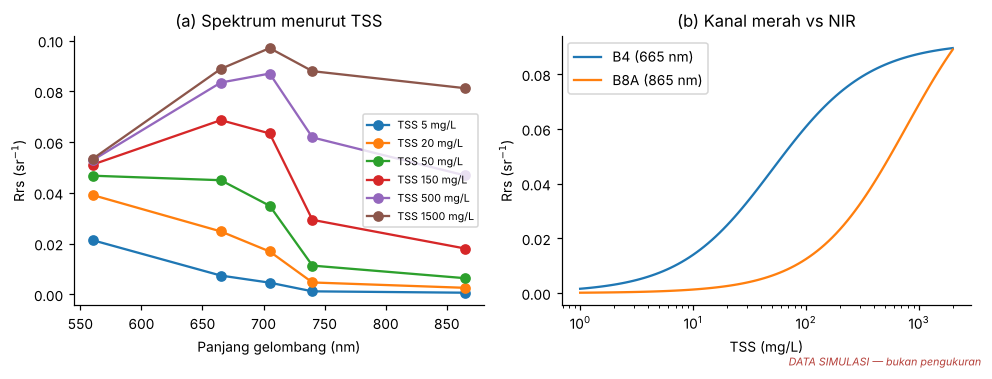

In [2]:
BANDS = {"B3": 560, "B4": 665, "B5": 705, "B6": 740, "B8A": 865}       # nm
AW  = {560: 0.062, 665: 0.43, 705: 0.70, 740: 2.70, 865: 4.60}       # absorpsi air (m^-1), ilustratif
BW  = {560: 0.0019, 665: 0.0009, 705: 0.0007, 740: 0.0006, 865: 0.0004}
APH = {560: 0.006, 665: 0.016, 705: 0.004, 740: 0.0005, 865: 0.0}    # absorpsi fitoplankton spesifik, ilustratif

def rrs_model(tss, chl=0.0, acdom443=0.3, bbp_star555=0.015):
    """Rrs (sr^-1) per kanal dari TSS (mg/L), klorofil-a (µg/L), dan CDOM. ILUSTRATIF."""
    out = {}
    for b, lam in BANDS.items():
        a = AW[lam] + 0.04 * np.exp(-0.0123 * (lam - 443)) * tss + APH[lam] * chl + acdom443 * np.exp(-0.015 * (lam - 443))
        bb = 0.5 * BW[lam] + bbp_star555 * (555 / lam) ** 0.5 * tss + 0.0006 * chl * (550 / lam)
        u = bb / (a + bb)
        r = 0.0949 * u + 0.0794 * u ** 2
        out[b] = 0.52 * r / (1 - 1.7 * r)
    return out

# Lihat perilaku spektral: kanal merah (B4) mulai jenuh pada TSS tinggi, NIR (B8A) terus naik
lam = list(BANDS.values())
fig, axs = plt.subplots(1, 2, figsize=(9, 3.4))
for t in [5, 20, 50, 150, 500, 1500]:
    R = rrs_model(t); axs[0].plot(lam, [R[b] for b in BANDS], "o-", label=f"TSS {t} mg/L")
axs[0].set(xlabel="Panjang gelombang (nm)", ylabel="Rrs (sr$^{-1}$)", title="(a) Spektrum menurut TSS")
axs[0].legend(fontsize=7)
tt = np.logspace(0, 3.3, 100)
for b in ["B4", "B8A"]:
    axs[1].plot(tt, [rrs_model(t)[b] for t in tt], label=f"{b} ({BANDS[b]} nm)")
axs[1].set(xscale="log", xlabel="TSS (mg/L)", ylabel="Rrs (sr$^{-1}$)", title="(b) Kanal merah vs NIR"); axs[1].legend()
stamp(fig); plt.tight_layout(); plt.show()

## 2. Pembangkit data simulasi
Fungsi ini membangkitkan **persis** data latih Bab 7 bila dipakai dengan seed 2026. Mahasiswa boleh mengubah parameternya untuk membuat skenario baru (lihat bagian 8).

**Sungai sintetik (Kasus 1).** 10 ruas berjarak 0,5–15,5 km dari sumber sedimen titik, 3 kampanye (K1, K2 kemarau; H1 hujan), dan 3 titik berdekatan dalam satu piksel per ruas, jadi totalnya 90 baris. Sifat partikel (`bstar`) sengaja dibuat berbeda per ruas.

**Waduk sintetik (Kasus 2).** 3 zona (riverin keruh, transisi, lakustrin), 4 kampanye (K1, K2 kemarau; H1, H2 hujan), dan 4 titik per zona, jadi totalnya 48 baris.

Derau ditambahkan untuk meniru galat laboratorium, sisa koreksi atmosfer per citra, dan derau piksel.

In [3]:
def make_data(seed=2026, bstar_sd=0.25, bstar_same=False, n_res_points=4,
              test_ruas=("R03", "R08"), test_camp="H2"):
    rng = np.random.default_rng(seed)
    # ---------------- Kasus 1: sungai sintetik
    rows = []
    ruas_d = np.linspace(0.5, 15.5, 10)
    bstar = 0.015 * np.exp(rng.normal(0, bstar_sd, 10))         # sifat partikel berbeda per ruas
    if bstar_same:
        bstar = np.full(10, 0.015)                               # angka acak tetap diambil agar derau lain identik
    camps = {"K1": ("kemarau", 20, 1500, 1.5), "K2": ("kemarau", 25, 1300, 1.7), "H1": ("hujan", 150, 800, 4.0)}
    for cname, (musim, base, peak, L) in camps.items():
        offset = {b: rng.normal(0, 0.0004) for b in BANDS}       # sisa koreksi atmosfer per citra
        for i, d in enumerate(ruas_d):
            tss_pix = (base + peak * np.exp(-d / L)) * np.exp(rng.normal(0, 0.10))
            R = rrs_model(tss_pix, acdom443=0.5, bbp_star555=bstar[i])
            Rpix = {b: max(R[b] * (1 + rng.normal(0, 0.03)) + offset[b], 1e-5) for b in BANDS}
            for k in range(3):                                    # 3 titik dalam satu piksel
                rows.append({"id": f"{cname}-R{i+1:02d}-{k+1}", "kampanye": cname, "musim": musim,
                             "ruas": f"R{i+1:02d}", "jarak_km": round(d, 2), "titik": k + 1,
                             **{f"Rrs_{b}": Rpix[b] for b in BANDS},
                             "TSS_mgL": tss_pix * np.exp(rng.normal(0, 0.08))})   # galat laboratorium
    river = pd.DataFrame(rows)
    river["peran"] = np.where(river.ruas.isin(test_ruas), "uji akhir", "pengembangan")
    # ---------------- Kasus 2: waduk sintetik
    ZONES = {"riverin": dict(chl=8, tss=(25, 70), cdom=0.6), "transisi": dict(chl=20, tss=(10, 25), cdom=0.45),
             "lakustrin": dict(chl=40, tss=(4, 8), cdom=0.3)}
    rows = []
    for cname, musim in {"K1": "kemarau", "K2": "kemarau", "H1": "hujan", "H2": "hujan"}.items():
        offset = {b: rng.normal(0, 0.0003) for b in BANDS}
        for z, p in ZONES.items():
            for k in range(n_res_points):
                chl = p["chl"] * (1.0 if musim == "kemarau" else 0.5) * np.exp(rng.normal(0, 0.35))
                tss = p["tss"][0 if musim == "kemarau" else 1] * np.exp(rng.normal(0, 0.25))
                R = rrs_model(tss, chl=chl, acdom443=p["cdom"] * np.exp(rng.normal(0, 0.15)), bbp_star555=0.012)
                Rp = {b: max(R[b] * (1 + rng.normal(0, 0.03)) + offset[b], 1e-5) for b in BANDS}
                rows.append({"id": f"{cname}-{z[:3].upper()}-{k+1}", "kampanye": cname, "musim": musim, "zona": z,
                             **{f"Rrs_{b}": Rp[b] for b in BANDS}, "TSS_mgL": tss,
                             "Chla_ugL": chl * np.exp(rng.normal(0, 0.08))})
    res = pd.DataFrame(rows)
    res["peran"] = np.where(res.kampanye == test_camp, "uji akhir", "pengembangan")
    return river, res

## 3. Memuat data latih
Ada tiga cara, dicoba berurutan:
1. **Dari link unduhan.** Isi `URL_SUNGAI` dan `URL_WADUK` dengan link CSV (mis. link *raw* GitHub atau Zenodo).
2. **Dari berkas CSV.** Unggah `kasus1_sungai_sintetik_SIMULASI.csv` dan `kasus2_waduk_sintetik_SIMULASI.csv` lewat ikon folder 📁 di panel kiri Colab.
3. **Dibangkitkan ulang** dengan fungsi di bagian 2 (seed 2026).

Ketiganya menghasilkan data yang sama. Sel ini juga memeriksa kesamaan itu.

In [4]:
URL_SUNGAI = ""   # contoh: "https://raw.githubusercontent.com/<akun>/<repo>/main/data/kasus1_sungai_sintetik_SIMULASI.csv"
URL_WADUK  = ""   # contoh: "https://raw.githubusercontent.com/<akun>/<repo>/main/data/kasus2_waduk_sintetik_SIMULASI.csv"
F_SUNGAI, F_WADUK = "kasus1_sungai_sintetik_SIMULASI.csv", "kasus2_waduk_sintetik_SIMULASI.csv"

gen_river, gen_res = make_data(seed=2026)
if URL_SUNGAI and URL_WADUK:
    river, res = pd.read_csv(URL_SUNGAI, float_precision="round_trip"), pd.read_csv(URL_WADUK, float_precision="round_trip"); sumber = "link unduhan"
elif os.path.exists(F_SUNGAI) and os.path.exists(F_WADUK):
    river, res = pd.read_csv(F_SUNGAI, float_precision="round_trip"), pd.read_csv(F_WADUK, float_precision="round_trip"); sumber = "berkas CSV"
else:
    river, res = gen_river, gen_res; sumber = "dibangkitkan ulang (seed 2026)"
print("Sumber data:", sumber)

# float_precision="round_trip" membaca angka sampai digit terakhir; Random Forest peka terhadap selisih sekecil apa pun
# Periksa: data yang dimuat sama persis dengan data bangkitan
num = lambda df: df.select_dtypes("number").values
sama = np.array_equal(num(river), num(gen_river)) and np.array_equal(num(res), num(gen_res))
print("Sama dengan data Bab 7:", sama)
print(f"Sungai: {len(river)} baris | Waduk: {len(res)} baris")
river.head(6)

Sumber data: berkas CSV
Sama dengan data Bab 7: True
Sungai: 90 baris | Waduk: 48 baris


,id,kampanye,musim,ruas,jarak_km,titik,Rrs_B3,Rrs_B4,Rrs_B5,Rrs_B6,Rrs_B8A,TSS_mgL,peran
0,K1-R01-1,K1,kemarau,R01,0.50,1,0.0465,0.0831,0.0888,0.0709,0.0624,1085.1268,pengembangan
1,K1-R01-2,K1,kemarau,R01,0.50,2,0.0465,0.0831,0.0888,0.0709,0.0624,1010.6407,pengembangan
2,K1-R01-3,K1,kemarau,R01,0.50,3,0.0465,0.0831,0.0888,0.0709,0.0624,1017.4184,pengembangan
3,K1-R02-1,K1,kemarau,R02,2.17,1,0.0576,0.0817,0.0888,0.0552,0.0422,362.9932,pengembangan
4,K1-R02-2,K1,kemarau,R02,2.17,2,0.0576,0.0817,0.0888,0.0552,0.0422,444.1059,pengembangan
5,K1-R02-3,K1,kemarau,R02,2.17,3,0.0576,0.0817,0.0888,0.0552,0.0422,426.0941,pengembangan


## 4. Metrik dan validasi silang (Bab 6)
- **MAE, RMSE, bias** dalam satuan asli
- **bias log** = $10^{\overline{\log_{10}(P/O)}}$: 1 berarti tanpa bias, 1,2 berarti rata-rata 20% terlalu tinggi
- **MAE log** = $10^{\overline{|\log_{10}(P/O)|}}$, sehingga **kesalahan relatif** = (MAE log − 1) × 100%

Validasi silang dijalankan dengan tiga cara: **acak 5-lipatan**, **per kelompok lokasi** (ruas/zona disisihkan satu per satu), dan **per kampanye**.

In [5]:
def metrics(obs, pred):
    obs, pred = np.asarray(obs, float), np.asarray(pred, float)
    e = pred - obs
    ok = (obs > 0) & (pred > 0)
    le = np.log10(pred[ok]) - np.log10(obs[ok])
    return {"n": int(len(obs)), "MAE": float(np.mean(np.abs(e))), "RMSE": float(np.sqrt(np.mean(e ** 2))),
            "bias": float(np.mean(e)), "bias_log": float(10 ** np.mean(le)), "MAE_log": float(10 ** np.mean(np.abs(le))),
            "R2": float(1 - np.sum(e ** 2) / np.sum((obs - obs.mean()) ** 2))}
pct = lambda m: (m["MAE_log"] - 1) * 100            # kesalahan relatif (%)

def cv_predict(fit_fn, df, splitter, groups=None):
    """Prediksi validasi silang: setiap baris diprediksi oleh model yang TIDAK melihat baris itu."""
    pred = np.full(len(df), np.nan)
    for tr, te in splitter.split(df, groups=groups):
        pred[te] = fit_fn(df.iloc[tr])(df.iloc[te])
    return pred

def run_cv(models, splits, dev, target):
    return {(m, s): metrics(dev[target], cv_predict(fn, dev, sp, g))
            for m, fn in models.items() for s, (sp, g) in splits.items()}

def pick_simplest(models, res, split, tol=0.02):
    """Aturan Bab 5: model PALING SEDERHANA (urutan daftar) yang selisihnya <= 2% dari yang terbaik."""
    best = min(res[(m, split)]["MAE_log"] for m in models)
    return next(m for m in models if res[(m, split)]["MAE_log"] <= best * (1 + tol))

def cv_table(res, models, splits):
    t = pd.DataFrame({s: [round(pct(res[(m, s)]), 1) for m in models] for s in splits}, index=list(models))
    t.index.name = "kesalahan relatif (%)"; return t

## 5. Kasus 1: Sungai sintetik (TSS)
Ruas **R03** dan **R08** disisihkan sejak awal sebagai **data uji akhir** (kolom `peran`).

### 5.1 Empat kandidat model (Bab 5)
- **M1** regresi log-TSS terhadap log Rrs(B4)
- **M2** semi-empiris satu kanal merah, bentuk Nechad et al. (2010)
- **M3** peralihan merah→NIR mengikuti gagasan Dogliotti et al. (2015); ambang ρ 0,12–0,20 **ilustratif**
- **M4** Random Forest dengan 4 kanal

In [6]:
dev1 = river[river.peran == "pengembangan"].reset_index(drop=True)
test1 = river[river.peran == "uji akhir"].reset_index(drop=True)
print(f"Pengembangan: {len(dev1)} baris | Uji akhir: {len(test1)} baris (ruas {sorted(test1.ruas.unique())})")

def fit_loglin(d, band="Rrs_B4"):
    b, a = np.polyfit(np.log10(d[band]), np.log10(d.TSS_mgL), 1)
    return lambda q: 10 ** (a + b * np.log10(q[band]))

def fit_nechad(d, band="Rrs_B4"):
    """TSS = A·ρ / (1 − ρ/C), dikalibrasi dalam skala log; C dijaga > ρ maksimum data latih."""
    rho = np.pi * d[band].values; rmax = rho.max()
    f = lambda r, logA, k: logA + np.log10(r) - np.log10(np.clip(1 - r / (rmax * (1 + np.exp(k))), 1e-3, None))
    p, _ = curve_fit(f, rho, np.log10(d.TSS_mgL.values), p0=[3, 0], maxfev=20000)
    A, Cc = 10 ** p[0], rmax * (1 + np.exp(p[1]))
    return lambda q: A * (np.pi * q[band].values) / np.clip(1 - np.pi * q[band].values / Cc, 1e-3, None)

def make_switch(lo=0.12, hi=0.20):
    """Bobot berpindah dari model merah ke model NIR ketika ρ(B4) naik dari lo ke hi."""
    def fit(d):
        red, nir = fit_nechad(d, "Rrs_B4"), fit_nechad(d, "Rrs_B8A")
        def f(q):
            w = np.clip((np.pi * q["Rrs_B4"].values - lo) / (hi - lo), 0, 1)
            return (1 - w) * red(q) + w * nir(q)
        return f
    return fit

FEATS1 = ["Rrs_B3", "Rrs_B4", "Rrs_B5", "Rrs_B8A"]
FEATS2 = ["Rrs_B3", "Rrs_B4", "Rrs_B5", "Rrs_B6", "Rrs_B8A"]
def fit_rf(d, feats=FEATS1, target="TSS_mgL"):
    m = RandomForestRegressor(n_estimators=300, random_state=0).fit(d[feats], np.log10(d[target]))
    return lambda q: 10 ** m.predict(q[feats])

models1 = {"M1 regresi log (B4)": fit_loglin, "M2 semi-empiris merah": fit_nechad,
           "M3 peralihan merah→NIR": make_switch(0.12, 0.20), "M4 Random Forest": fit_rf}

Pengembangan: 72 baris | Uji akhir: 18 baris (ruas ['R03', 'R08'])


### 5.2 Validasi silang: acak vs per ruas vs per kampanye
Perhatikan selisih hasil **acak** dan **per ruas**, terutama untuk Random Forest. Bandingkan dengan **Tabel 7.4**.

In [7]:
splits1 = {"acak 5-lipatan": (KFold(5, shuffle=True, random_state=1), None),
           "per ruas": (LeaveOneGroupOut(), dev1.ruas.values),
           "per kampanye": (LeaveOneGroupOut(), dev1.kampanye.values)}
res1 = run_cv(models1, splits1, dev1, "TSS_mgL")
tab1 = cv_table(res1, models1, splits1); tab1

,acak 5-lipatan,per ruas,per kampanye
kesalahan relatif (%),,,
M1 regresi log (B4),51.6,63.4,54.2
M2 semi-empiris merah,50.4,80.8,78.8
M3 peralihan merah→NIR,22.6,28.1,26.2
M4 Random Forest,9.4,28.1,34.4


### 5.3 Pilih model dan uji akhir
Model dipilih dari validasi **per ruas**, lalu diuji **satu kali** pada ruas R03 dan R08. Random Forest ditampilkan sebagai pembanding.

In [8]:
best1 = pick_simplest(models1, res1, "per ruas")
print("Model terpilih:", best1)
fit_best1, fit_rf1 = models1[best1](dev1), fit_rf(dev1)
test1 = test1.assign(pred_terpilih=fit_best1(test1), pred_RF=fit_rf1(test1))
uji1 = pd.DataFrame({best1 + " (terpilih)": metrics(test1.TSS_mgL, test1.pred_terpilih),
                     "M4 Random Forest (pembanding)": metrics(test1.TSS_mgL, test1.pred_RF)})
uji1.round(3)

Model terpilih: M3 peralihan merah→NIR


,M3 peralihan merah→NIR (terpilih),M4 Random Forest (pembanding)
n,18.000,18.000
MAE,62.739,94.843
RMSE,89.307,124.923
bias,-47.433,-59.824
bias_log,0.864,0.660
MAE_log,1.521,1.877
R2,0.600,0.218


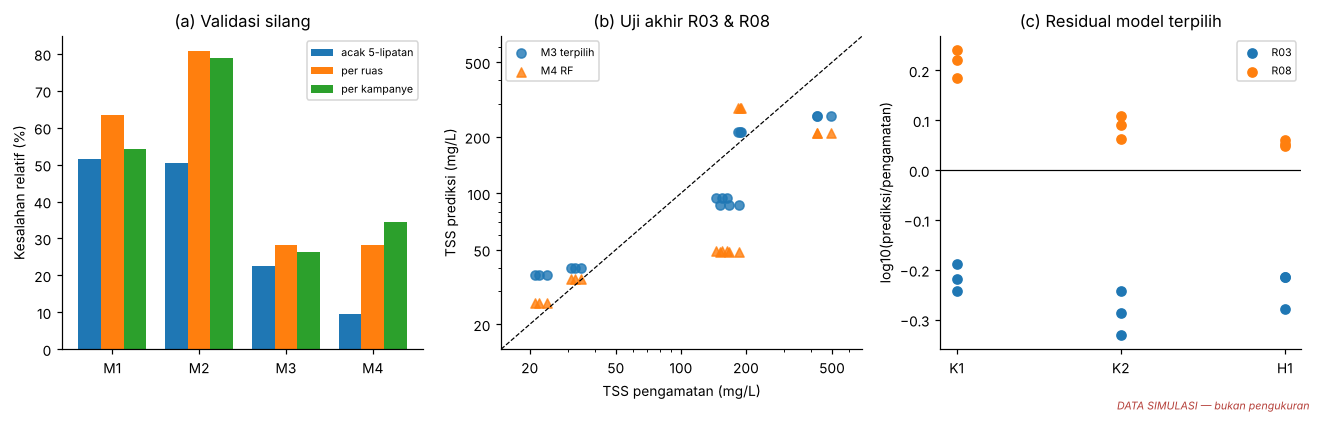

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.8))
ax = axs[0]; x = np.arange(len(models1)); w = 0.26
for k, s in enumerate(splits1):
    ax.bar(x + (k - 1) * w, tab1[s], w, label=s)
ax.set_xticks(x, [m.split(" ")[0] for m in models1]); ax.set(ylabel="Kesalahan relatif (%)", title="(a) Validasi silang")
ax.legend(fontsize=7)
ax = axs[1]
for col, lab, mk in [("pred_terpilih", best1.split(" ")[0] + " terpilih", "o"), ("pred_RF", "M4 RF", "^")]:
    ax.scatter(test1.TSS_mgL, test1[col], marker=mk, label=lab, alpha=0.8)
lim = [test1[["TSS_mgL", "pred_terpilih", "pred_RF"]].min().min() * 0.7, test1[["TSS_mgL", "pred_terpilih", "pred_RF"]].max().max() * 1.4]
ax.plot(lim, lim, "k--", lw=0.8); ax.set(xscale="log", yscale="log", xlim=lim, ylim=lim,
        xlabel="TSS pengamatan (mg/L)", ylabel="TSS prediksi (mg/L)", title="(b) Uji akhir R03 & R08"); ax.legend(fontsize=7)
from matplotlib.ticker import NullFormatter, FixedLocator, ScalarFormatter
for a_ in (ax.xaxis, ax.yaxis):
    a_.set_major_locator(FixedLocator([20, 50, 100, 200, 500])); a_.set_major_formatter(ScalarFormatter()); a_.set_minor_formatter(NullFormatter())
ax = axs[2]
for r, g in test1.groupby("ruas"):
    ax.scatter(g.kampanye, np.log10(g.pred_terpilih / g.TSS_mgL), label=r)
ax.axhline(0, color="k", lw=0.8); ax.set(ylabel="log10(prediksi/pengamatan)", title="(c) Residual model terpilih")
ax.legend(fontsize=7)
stamp(fig); plt.tight_layout(); plt.show()

**Yang perlu diperhatikan**
- Random Forest tampak paling baik pada validasi acak, tetapi kesalahannya naik tajam bila ruas disisihkan. Penyebabnya: tiga titik dalam satu piksel tersebar ke data latih dan data uji, sehingga model "sudah melihat" pikselnya (kebocoran informasi, Bab 6).
- Model M3 yang bermakna fisik lebih stabil dan lebih baik pada uji akhir.

## 6. Kasus 2: Waduk sintetik (klorofil-a)
Kampanye **H2** disisihkan sebagai data uji akhir, meniru pemakaian model pada waktu lain.

### 6.1 Tiga kandidat dan validasi silang
- **M1** NDCI (Mishra & Mishra, 2012) + regresi log
- **M2** model tiga kanal (Gitelson et al., 2008) + regresi log
- **M3** Random Forest

Perhatikan lonjakan kesalahan bila **satu zona disisihkan**. Bandingkan dengan **Tabel 7.5**.

In [10]:
for df in (res,):
    df["NDCI"] = (df.Rrs_B5 - df.Rrs_B4) / (df.Rrs_B5 + df.Rrs_B4)
    df["TBM"] = (1 / df.Rrs_B4 - 1 / df.Rrs_B5) * df.Rrs_B6
dev2 = res[res.peran == "pengembangan"].reset_index(drop=True)
test2 = res[res.peran == "uji akhir"].reset_index(drop=True)
print(f"Pengembangan: {len(dev2)} baris | Uji akhir: {len(test2)} baris (kampanye {sorted(test2.kampanye.unique())})")

def fit_lin_log(d, feat):
    b, a = np.polyfit(d[feat], np.log10(d.Chla_ugL), 1)
    return lambda q: 10 ** (a + b * q[feat].values)

models2 = {"M1 NDCI + regresi log": lambda d: fit_lin_log(d, "NDCI"),
           "M2 tiga kanal + regresi log": lambda d: fit_lin_log(d, "TBM"),
           "M3 Random Forest": lambda d: fit_rf(d, FEATS2, "Chla_ugL")}
splits2 = {"acak 5-lipatan": (KFold(5, shuffle=True, random_state=1), None),
           "per zona": (LeaveOneGroupOut(), dev2.zona.values),
           "per kampanye": (LeaveOneGroupOut(), dev2.kampanye.values)}
res2 = run_cv(models2, splits2, dev2, "Chla_ugL")
tab2 = cv_table(res2, models2, splits2); tab2

Pengembangan: 36 baris | Uji akhir: 12 baris (kampanye ['H2'])


,acak 5-lipatan,per zona,per kampanye
kesalahan relatif (%),,,
M1 NDCI + regresi log,45.2,73.8,44.6
M2 tiga kanal + regresi log,48.7,102.8,49.3
M3 Random Forest,44.4,73.5,50.8


### 6.2 Uji akhir dan uji keteralihan
Model dipilih dari validasi **per kampanye**. Bandingkan **bias** (µg/L) dengan **bias log**: yang pertama bisa mendekati nol, padahal yang kedua menunjukkan model rata-rata terlalu tinggi.

**Uji keteralihan:** model NDCI dikalibrasi hanya di zona lakustrin, lalu diterapkan ke zona riverin.

In [11]:
best2 = pick_simplest(models2, res2, "per kampanye")
print("Model terpilih:", best2)
test2 = test2.assign(pred_terpilih=models2[best2](dev2)(test2))
lak, riv = dev2[dev2.zona == "lakustrin"], dev2[dev2.zona == "riverin"].copy()
riv["pred_transfer"] = fit_lin_log(lak, "NDCI")(riv)
uji2 = pd.DataFrame({best2 + " — uji akhir H2": metrics(test2.Chla_ugL, test2.pred_terpilih),
                     "NDCI lakustrin → riverin": metrics(riv.Chla_ugL, riv.pred_transfer)})
uji2.round(3)

Model terpilih: M1 NDCI + regresi log


,M1 NDCI + regresi log — uji akhir H2,NDCI lakustrin → riverin
n,12.000,12.000
MAE,4.746,12.032
RMSE,7.037,12.333
bias,-0.688,12.032
bias_log,1.271,2.929
MAE_log,1.696,2.929
R2,0.561,-9.991


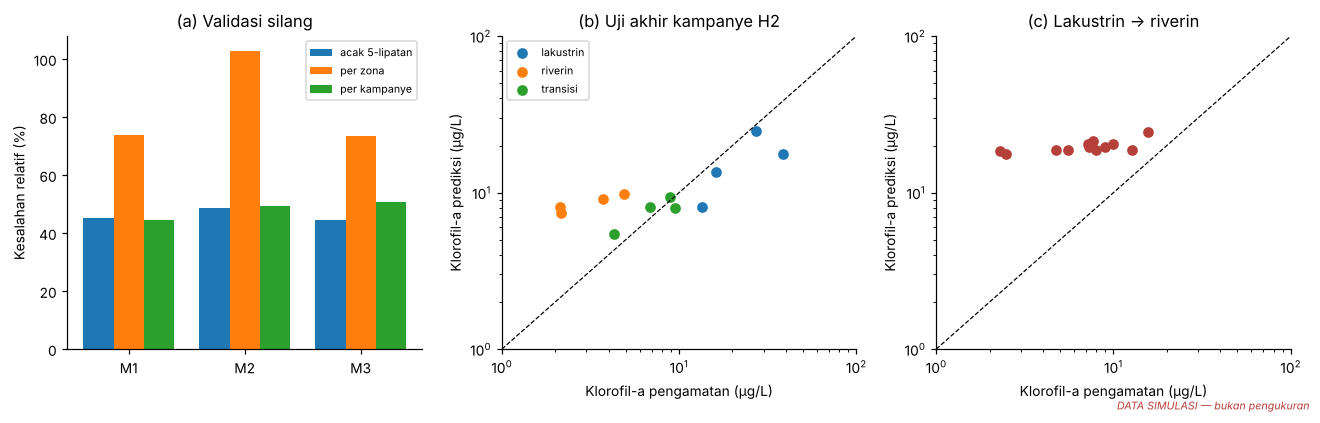

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.8))
ax = axs[0]; x = np.arange(len(models2)); w = 0.26
for k, s in enumerate(splits2):
    ax.bar(x + (k - 1) * w, tab2[s], w, label=s)
ax.set_xticks(x, [m.split(" ")[0] for m in models2]); ax.set(ylabel="Kesalahan relatif (%)", title="(a) Validasi silang")
ax.legend(fontsize=7)
ax = axs[1]
for z, g in test2.groupby("zona"):
    ax.scatter(g.Chla_ugL, g.pred_terpilih, label=z)
lim = [1, 100]; ax.plot(lim, lim, "k--", lw=0.8)
ax.set(xscale="log", yscale="log", xlim=lim, ylim=lim, xlabel="Klorofil-a pengamatan (µg/L)",
       ylabel="Klorofil-a prediksi (µg/L)", title="(b) Uji akhir kampanye H2"); ax.legend(fontsize=7)
ax = axs[2]
ax.scatter(riv.Chla_ugL, riv.pred_transfer, c="#B5403A")
ax.plot(lim, lim, "k--", lw=0.8)
ax.set(xscale="log", yscale="log", xlim=lim, ylim=lim, xlabel="Klorofil-a pengamatan (µg/L)",
       ylabel="Klorofil-a prediksi (µg/L)", title="(c) Lakustrin → riverin")
stamp(fig); plt.tight_layout(); plt.show()

**Yang perlu diperhatikan**
- Menyisihkan satu zona menaikkan kesalahan secara tajam karena setiap zona punya kombinasi sedimen, CDOM, dan klorofil-a yang khas.
- Model kompleks (Random Forest) tidak lebih baik daripada NDCI, sehingga model sederhana yang dipilih.
- Model yang dikalibrasi di zona jernih **terlalu tinggi** bila dipakai di zona keruh. Model tidak otomatis dapat dipindahkan ke kondisi optik lain (Bab 6).

## 7. Unduh hasil
Sel ini menyimpan data, tabel validasi, dan metrik uji akhir ke satu berkas ZIP. Di Colab, unduhan dimulai otomatis.

In [13]:
ringkasan = {"catatan": LBL, "kasus1": {"model_terpilih": best1, "validasi_silang_persen": tab1.to_dict(),
             "uji_akhir": uji1.to_dict()}, "kasus2": {"model_terpilih": best2,
             "validasi_silang_persen": tab2.to_dict(), "uji_akhir_dan_transfer": uji2.to_dict()}}
with zipfile.ZipFile("hasil_latihan_bab7_SIMULASI.zip", "w") as z:
    z.writestr("kasus1_sungai_sintetik_SIMULASI.csv", river.drop(columns=[c for c in river if c.startswith("pred")], errors="ignore").to_csv(index=False))
    z.writestr("kasus2_waduk_sintetik_SIMULASI.csv", res.to_csv(index=False))
    z.writestr("tabel_validasi_kasus1.csv", tab1.to_csv()); z.writestr("tabel_validasi_kasus2.csv", tab2.to_csv())
    z.writestr("ringkasan_hasil_SIMULASI.json", json.dumps(ringkasan, indent=2, ensure_ascii=False))
print("Tersimpan: hasil_latihan_bab7_SIMULASI.zip")
try:
    from google.colab import files; files.download("hasil_latihan_bab7_SIMULASI.zip")
except ImportError:
    print("(Bukan di Colab: berkas ada di folder kerja.)")

Tersimpan: hasil_latihan_bab7_SIMULASI.zip
(Bukan di Colab: berkas ada di folder kerja.)


## 8. Latihan untuk mahasiswa
Pembahasan lengkap kelima latihan ini ada di **Lampiran A**. Kerjakan dulu sebelum membaca pembahasannya.

1. **Ganti ruas uji.** Ubah `test_ruas` di `make_data()` (mis. `("R01", "R06")`), lalu jalankan ulang bagian 5. Apakah model yang terpilih tetap sama? Seberapa stabil hasil uji akhirnya?
2. **Samakan sifat partikel.** Bangkitkan data dengan `make_data(bstar_same=True)`. Apakah selisih validasi acak dan per ruas mengecil?
3. **Tambah titik di waduk.** Pakai `make_data(n_res_points=12)`. Apakah Random Forest menjadi lebih baik daripada NDCI?
4. **Ubah ambang peralihan merah→NIR.** Coba `make_switch(0.05, 0.08)` dan `make_switch(0.20, 0.30)`. Bagaimana pengaruhnya pada M3?
5. **Uji kebocoran informasi.** Ambil satu titik per piksel saja (`river[river.titik == 1]`), lalu bandingkan validasi acak Random Forest dengan hasil memakai tiga titik.

Cara cepat mengganti data: jalankan sel berikut, lalu jalankan ulang mulai bagian 5.

In [14]:
# Contoh Latihan 2: sifat partikel sama di semua ruas (hapus tanda # untuk mencoba)
# river, res = make_data(bstar_same=True)
# Contoh Latihan 3: 12 titik per zona di waduk
# river, res = make_data(n_res_points=12)